# Lab 11: RNN attention

Guidelines: https://github.com/MohammedMosuily/NLP_lab11

Run cells from top to bottom from this folder.

## Load and prepare the data

Use the CSV supplied with the lab. Lowercase the questions, remove punctuation,
give words numbers, and add padding.

In [1]:
import re
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence
import matplotlib.pyplot as plt

torch.manual_seed(42)
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
tokens = [re.sub(r"[^a-z\s]", "", question.lower()).split() for question in df["question"]]
vocabulary = sorted({word for question in tokens for word in question})
word_index = {word: i + 1 for i, word in enumerate(vocabulary)}
X = pad_sequence(
    [torch.tensor([word_index[word] for word in question]) for question in tokens],
    batch_first=True,
)
y = torch.tensor(df["answer_id"].to_numpy(), dtype=torch.long)
assert sorted(y.unique().tolist()) == list(range(df["answer_id"].nunique()))
print("Questions:", len(df), "Answer groups:", df["answer_id"].nunique())
print(df.head().to_string(index=False))

Questions: 168 Answer groups: 12
            question  answer_id               answer
    Do you get hurt?          0 I don't have a body.
Do you have fingers?          0 I don't have a body.
 Do you ever breathe          0 I don't have a body.
   Do you masticate?          0 I don't have a body.
   Can you throw up?          0 I don't have a body.


## Build and train the RNN

`batch_first=True` makes the RNN read each question across its words.
Give padding zero attention, and clear gradients before each update.

In [2]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        hidden, _ = self.rnn(self.emb(x))
        scores = self.att(hidden).squeeze(-1)
        scores = scores.masked_fill(x == 0, float("-inf"))
        weights = torch.softmax(scores, dim=1)
        context = (hidden * weights.unsqueeze(-1)).sum(1)
        return self.fc(context), weights

model = RNN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
model.train()
for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y)
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}: loss = {loss.item():.4f}")

model.eval()
with torch.no_grad():
    predictions, weights = model(X)
    single_prediction, _ = model(X[:1])

assert torch.allclose(weights.sum(1), torch.ones(len(X)))
assert torch.all(weights[X == 0] == 0)
assert torch.allclose(predictions[:1], single_prediction, atol=1e-5)
print("Training accuracy:", (predictions.argmax(1) == y).float().mean().item())

Epoch 10: loss = 1.8904
Epoch 20: loss = 1.0504
Epoch 30: loss = 0.4775
Epoch 40: loss = 0.1759
Epoch 50: loss = 0.0608
Training accuracy: 0.9940476417541504


## Task 1: Attention for three questions

Question: Do you get hurt?
Highest attention: get (0.597)


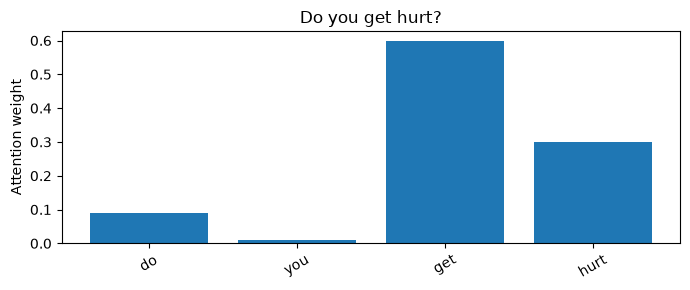

Question: Are you old?
Highest attention: old (0.979)


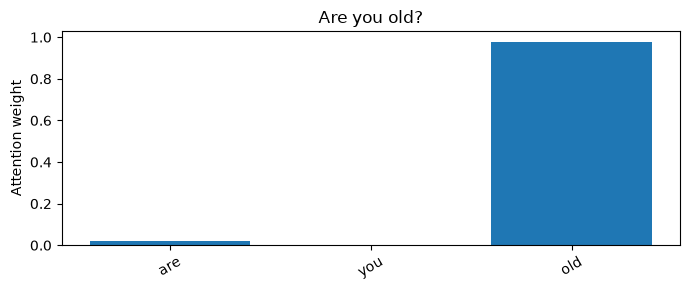

Question: Who programmed you?
Highest attention: programmed (0.471)


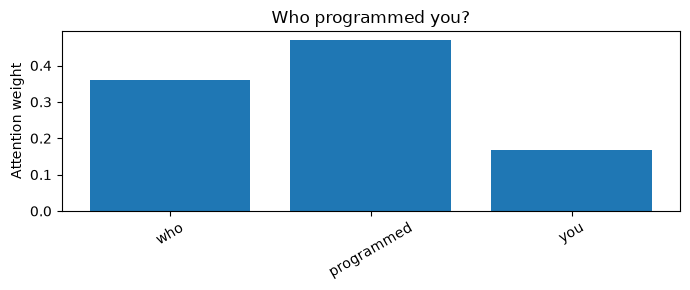

In [3]:
def show_attention(indices):
    for i in indices:
        words = tokens[i]
        values = weights[i, :len(words)].tolist()
        best_word = words[values.index(max(values))]
        print("Question:", df.loc[i, "question"])
        print("Highest attention:", best_word, f"({max(values):.3f})")

        plt.figure(figsize=(7, 3))
        plt.bar(words, values)
        plt.title(df.loc[i, "question"])
        plt.ylabel("Attention weight")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()

show_attention([0, 14, 42])

For these three questions, the highest weights are on `get`, `old`, and
`programmed`. The last two words clearly describe the question topic. `get` is
less useful on its own, so the highest-weight word is not always the one I would
choose as most important.

## Task 2: Similar questions, different wording

Both questions ask about age and have the same answer group.

Question: How old are you?
Highest attention: are (0.422)


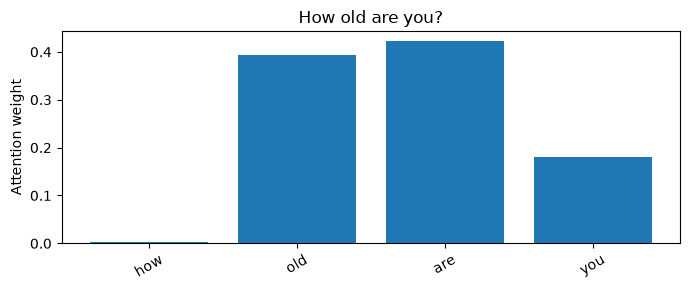

Question: What's your age?
Highest attention: age (0.995)


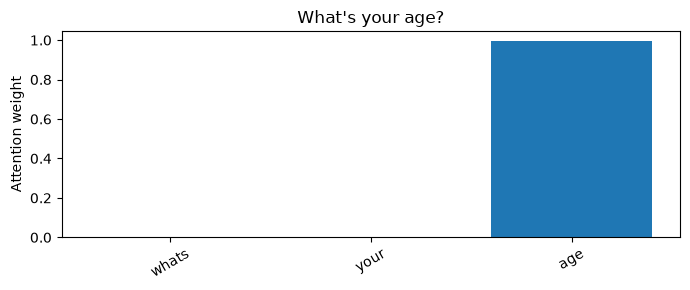

In [4]:
similar_questions = ["How old are you?", "What's your age?"]
indices = [df.index[df["question"] == question][0] for question in similar_questions]
assert df.loc[indices, "answer_id"].nunique() == 1
show_attention(indices)

The model focuses most on `are` in "How old are you?" and `age` in
"What's your age?". Both questions ask the same thing, but the strongest words
are different. Attention depends on the wording and context learned by the model;
it does not always focus on the clearest topic word.

All questions were used for training, as in the lab example. These charts and
the training accuracy do not measure performance on new questions.